# Hospital cost drivers: a step-by-step walkthrough

**Question:** what drives California hospital operating costs up between 2004 and 2024?

This notebook follows the real pipeline from raw files to the dashboard. It calls the same functions in `src/`, so the numbers here are the numbers in `outputs/`.

| Part | What happens | Code |
|---|---|---|
| 1 | Load raw files and pivots | `src/load.py` |
| 2 | Clean the data and choose hospitals | `src/clean.py` |
| 3 | Build measures such as FTEs and cost per FTE | `src/features.py` |
| 4 | Summarize by year | `src/analysis.py` |
| 5 | Split employee-cost growth into its drivers | `src/decompose.py` |
| 6 | Look beyond labor | `src/analysis.py` |
| 7 | Compare with the old notebooks | `analysis_NB/` |
| 8 | Test how much the choices matter | `src/pipeline.py` |
| 9 | Feed the dashboard | `src/dashboard_data.py` |

This notebook only reads data. It doesn't change anything in `outputs/`. All dollars are nominal, because the medical CPI file hasn't been added yet.

In [1]:
import sys, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd()))
import config
from src import analysis, clean, decompose, features, load, plots

pd.set_option("display.max_columns", 30, "display.width", 160)
pd.options.display.float_format = "{:,.2f}".format
YEARS = config.YEARS

## 1. Load the raw data

Each year has two sources:

- **Raw file:** the HCAI hospital report, with one row per report filed.
- **Pivot file:** adds adjusted patient days, which count outpatient work as well as inpatient days.

In [2]:
pd.DataFrame({
    "raw file": config.RAW_FILES,
    "pivot file": config.PIVOT_FILES,
}).rename_axis("year")

,raw file,pivot file
year,,
2004,cy-selected-file-hafd2004revised906.xls,hafd2004pivot.xls
2009,cy-selected-file-hafd09-revised911.xlsx,hafd2009pivot.xls
2014,hafd14-42017-extract.xlsx,hafd2014pivot.xls
2019,hadr-19.xlsx,hafd2019pivot.xls
2024,hadr-2024.xlsx,hafd2024pivot.xlsm


### Column names change by year

HCAI spells some columns differently from year to year. `normalize_columns` removes stray spaces and uppercases each name, then `config.COLUMN_ALIASES` maps known variants to one name. Without this, 2024 would look like it had no `NAT_BIRTHS` column.

In [3]:
messy = pd.DataFrame(columns=["BLDGS \n", "NAT_0BIRTHS", "PD_HR_NO", "CURR_LIAB", "EXP_SAL"])
pd.DataFrame({"as filed": messy.columns, "after cleaning": load.normalize_columns(messy).columns})

,as filed,after cleaning
0,BLDGS \n,BLDGS
1,NAT_0BIRTHS,NAT_BIRTHS
2,PD_HR_NO,PD_HR_NON
3,CURR_LIAB,CUR_LIAB
4,EXP_SAL,EXP_SAL


In [4]:
raw = load.load_raw()
pivots = load.load_pivots()
print(f"Raw rows: {len(raw):,}   Pivot rows: {len(pivots):,}")
raw.groupby("FILE_YEAR").agg(rows=("FAC_NO", "size"), hospitals=("FAC_NO", "nunique"))

Raw rows: 2,253   Pivot rows: 2,226


,rows,hospitals
FILE_YEAR,,
2004,461,454
2009,449,447
2014,450,444
2019,449,442
2024,444,438


`load_raw` keeps only the columns listed in `config.py` and prints a warning if one is missing. No warning appeared above, so every year has all of them.

## 2. Clean the data

### 2a. Fix types and set the year

`coerce` makes numbers numeric, parses dates and uppercases labels. That matters because 2004 says `COMPARABLE` and later years say `Comparable`.

`YEAR` is the year of `END_DATE`. Hospitals use different fiscal years, so a report ending June 2004 runs mostly through late 2003 and still counts as 2004.

In [5]:
typed = clean.coerce(raw)
print("Reports ending outside their file's year:", (typed["YEAR"] != typed["FILE_YEAR"]).sum())
typed["TYPE_HOSP"].value_counts()

Reports ending outside their file's year: 0


TYPE_HOSP
COMPARABLE              1890
KAISER                   161
PHF                      123
STATE                     44
LTC EMPHASIS              19
OTHER NON-COMPARABLE      16
Name: count, dtype: int64

### 2b. Combine multiple reports for one hospital

A hospital can file more than one report in a year, for example after an ownership change. `collapse_reports` makes one row per hospital-year by adding the dollars, hours and patient counts.

The example below shows a catch: these reports can cover more than 12 months. This one adds up to 549 days. Part 8 tests whether that matters.

In [6]:
example = typed[(typed["FAC_NO"] == 106580996) & (typed["YEAR"] == 2019)]
display(example[["FAC_NAME", "BEG_DATE", "END_DATE", "DAY_PER", "TOT_OP_EXP"]])

collapsed = clean.collapse_reports(typed)
collapsed[(collapsed["FAC_NO"] == 106580996) & (collapsed["YEAR"] == 2019)][
    ["FAC_NAME", "BEG_DATE", "END_DATE", "DAY_PER", "TOT_OP_EXP", "N_REPORTS"]
]

,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,TOT_OP_EXP
1360,ADVENTIST HEALTH AND RIDEOUT,2018-07-01,2019-06-30,365,435833957
1361,ADVENTIST HEALTH AND RIDEOUT,2019-07-01,2019-12-31,184,235721959


,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,TOT_OP_EXP,N_REPORTS
2223,ADVENTIST HEALTH AND RIDEOUT,2018-07-01,2019-12-31,549,671555916,2


### 2c. Add adjusted patient days

Pivots usually keep one report per hospital-year, so they can cover fewer days than the raw reports. `join_pivots` scales adjusted days to match the raw coverage and marks those rows in `ADJ_DAYS_PRORATED`.

The first version of the pipeline left these rows blank. That dropped more hospitals in later years and bent the volume trend, so scaling is safer.

In [7]:
joined = clean.join_pivots(collapsed, pivots)
print("Hospital-years scaled:", joined["ADJ_DAYS_PRORATED"].sum(), "of", len(joined))
print("Hospital-years with no adjusted days:", joined["ADJPATDAYS"].isna().sum())

Hospital-years scaled: 26 of 2225
Hospital-years with no adjusted days: 0


### 2d. Choose the hospitals

This choice matters more than any other in the analysis.

- `all`: every hospital, including Kaiser, state and psychiatric facilities.
- `comparable`: only rows HCAI labels Comparable.
- `balanced`: comparable hospitals that report in all 5 years, so the hospital mix stays fixed. **Use this one for headline numbers.**

In [8]:
hospitals = {name: clean.select_cohort(joined, name) for name in ["all", "comparable", "balanced"]}
funnel = pd.DataFrame({name: frame.groupby("YEAR")["FAC_NO"].nunique() for name, frame in hospitals.items()})
display(funnel)
joined.groupby(["YEAR", "TYPE_HOSP"]).size().unstack(fill_value=0)

,all,comparable,balanced
YEAR,,,
2004,454,395,310
2009,447,373,310
2014,444,369,310
2019,442,366,310
2024,438,363,310


TYPE_HOSP,COMPARABLE,KAISER,LTC EMPHASIS,OTHER NON-COMPARABLE,PHF,STATE
YEAR,,,,,,
2004,395,28,3,2,16,10
2009,373,32,4,6,21,11
2014,369,34,4,2,26,9
2019,366,33,4,2,30,7
2024,363,34,4,1,30,6


## 3. Build the measures

`add_features` creates the measures used everywhere else:

| Measure | Definition |
|---|---|
| `LABOR` | Salaries + benefits. Physician and contract labor aren't included. |
| `FTE` | Paid hours ÷ 2,080 |
| `PATIENT_SHARE` | Productive hours in patient departments ÷ all productive hours |
| `LABOR_PATIENT`, `LABOR_OVERHEAD` | `LABOR` split by that share |
| `FTE_PATIENT`, `FTE_OVERHEAD` | Paid hours by department type ÷ 2,080 |
| `OVERHEAD_EXP` | Research, education, general, fiscal, administrative and unassigned costs |
| `COST_PER_ADJ_DAY` | Total expense ÷ adjusted days |

**Why paid hours?** They add up correctly when a hospital reports only part of a year, so cost per FTE stays a fair annual figure.

**Division by zero** gives a blank (`NaN`), not 0. A 0 would pull averages down without warning.

In [9]:
data = features.add_features(hospitals["balanced"])
cols = ["FAC_NAME", "YEAR", "LABOR", "FTE", "COST_PER_FTE", "PATIENT_SHARE", "ADJPATDAYS", "COST_PER_ADJ_DAY"]
data[data["YEAR"].eq(2024)].nlargest(5, "LABOR")[cols]

,FAC_NAME,YEAR,LABOR,FTE,COST_PER_FTE,PATIENT_SHARE,ADJPATDAYS,COST_PER_ADJ_DAY
1913,STANFORD HEALTH CARE,2024,3218775963,"16,560.48","194,364.92",0.50,"559,186.76","12,935.14"
1732,UCSF MEDICAL CENTER,2024,3080272879,"13,188.97","233,549.13",0.66,"528,957.13","11,245.68"
1383,UNIVERSITY OF CALIFORNIA DAVIS MEDICAL CENTER,2024,2355775091,"8,337.29","282,558.87",0.59,"390,643.59","9,888.77"
694,CEDARS-SINAI MEDICAL CENTER,2024,2289023638,"14,494.25","157,926.27",0.48,"484,435.08","8,891.12"
1908,SANTA CLARA VALLEY MEDICAL CENTER,2024,2042739613,"8,687.24","235,142.57",0.70,"381,340.42","8,815.12"


Here's the same arithmetic done by hand for one hospital, to show there's nothing hidden in the function.

In [10]:
row = data[data["YEAR"].eq(2024)].nlargest(1, "LABOR").iloc[0]
labor = row["EXP_SAL"] + row["EXP_BEN"]
fte = row["PAID_HRS"] / 2080
print(row["FAC_NAME"])
print(f"Salaries + benefits: ${labor:,.0f}")
print(f"Paid hours / 2,080:  {fte:,.0f} FTEs")
print(f"Cost per FTE:        ${labor / fte:,.0f}")
print(f"Function gave:       ${row['COST_PER_FTE']:,.0f}")

STANFORD HEALTH CARE
Salaries + benefits: $3,218,775,963
Paid hours / 2,080:  16,560 FTEs
Cost per FTE:        $194,365
Function gave:       $194,365


## 4. Summarize by year

Costs grew much faster than activity. The index table sets 2004 to 100 so measures of different sizes can be compared.

In [11]:
summary = analysis.yearly_summary(data)
index = analysis.indexed(summary)
show = summary[["hospitals", "total_exp", "labor", "discharges", "adj_days", "fte", "cost_per_fte", "overhead_exp_per_fte"]]
display(show.T)
index.round(0)

YEAR,2004,2009,2014,2019,2024
hospitals,310.00,310.00,310.00,310.00,310.00
total_exp,"41,377,859,570.00","59,484,814,480.00","75,770,787,496.00","103,994,611,927.00","143,296,961,896.00"
labor,"21,523,588,152.00","31,787,256,681.00","38,463,252,964.00","51,087,863,117.00","68,901,640,966.00"
discharges,"2,666,095.00","2,776,254.00","2,702,577.00","2,780,924.00","2,699,449.00"
adj_days,"20,957,951.66","22,264,359.77","22,761,599.71","25,203,699.18","28,315,971.82"
fte,"303,343.26","351,689.97","359,587.43","402,127.04","453,785.28"
cost_per_fte,"70,954.56","90,384.31","106,964.95","127,044.09","151,837.54"
overhead_exp_per_fte,"51,889.36","64,023.17","88,057.79","106,321.77","127,052.36"


,total_exp,labor,discharges,adj_days,fte,cost_per_fte,overhead_exp_per_fte,cost_per_adj_day
YEAR,,,,,,,,
2004,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
2009,144.00,148.00,104.00,106.00,116.00,127.00,123.00,135.00
2014,183.00,179.00,101.00,109.00,119.00,151.00,170.00,169.00
2019,251.00,237.00,104.00,120.00,133.00,179.00,205.00,209.00
2024,346.00,320.00,101.00,135.00,150.00,214.00,245.00,256.00


In [12]:
growth = (index.loc[YEARS[-1]] / 100).rename("2024 as a multiple of 2004")
growth.round(2).to_frame()

,2024 as a multiple of 2004
total_exp,3.46
labor,3.20
discharges,1.01
adj_days,1.35
fte,1.50
cost_per_fte,2.14
overhead_exp_per_fte,2.45
cost_per_adj_day,2.56


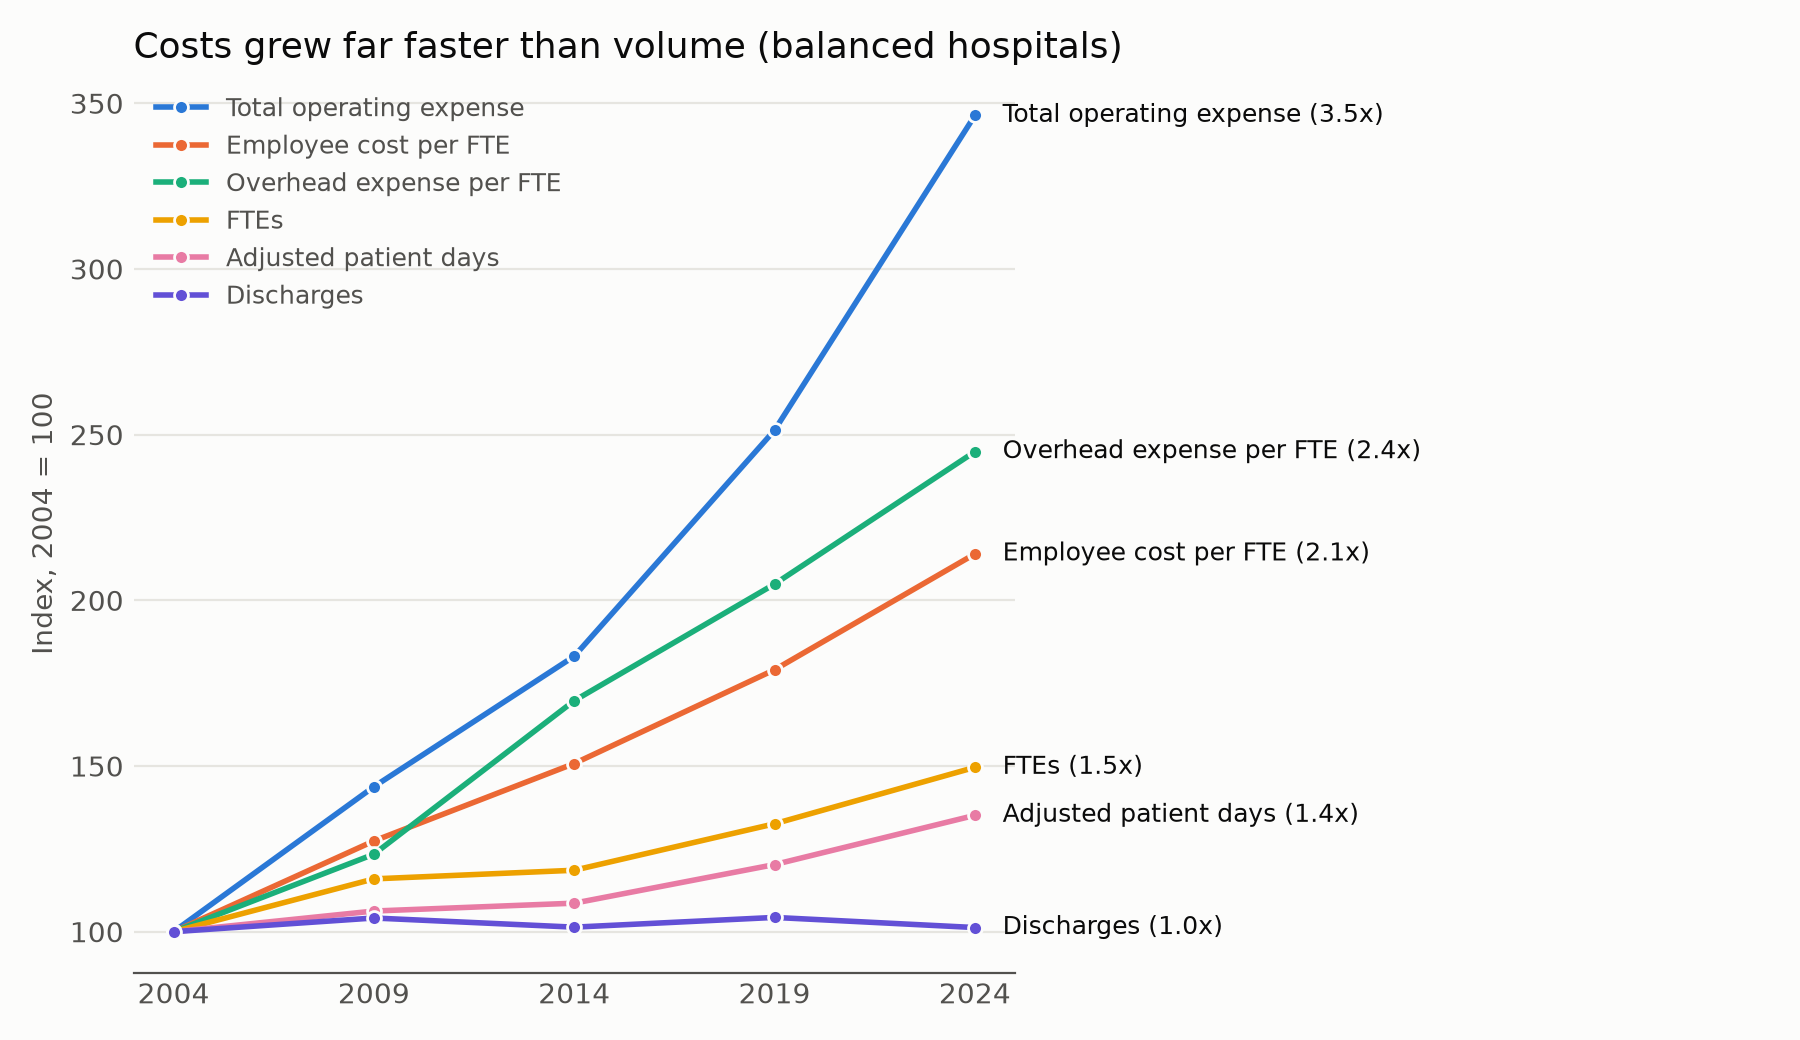

In [13]:
scratch = Path(tempfile.mkdtemp())
plots.plot_index(index, scratch / "index.png", "balanced")
display(Image(filename=str(scratch / "index.png"), width=760))

**How to read this:** discharges stayed flat, but that counts inpatients only. Adjusted patient days rose by about a third, so hospitals did do more work, much of it outpatient. FTEs rose faster than adjusted days, and cost per FTE roughly doubled.

Saying "volume barely moved" is only true for inpatient discharges.

## 5. Split employee-cost growth into its drivers

This is the core analysis. Employee cost is three things multiplied together:

$$\text{Employee cost} = \text{adjusted days} \times \frac{\text{FTEs}}{\text{adjusted day}} \times \text{cost per FTE}$$

So we can ask how much of the growth came from:

- **Volume:** more work
- **Staffing:** more FTEs per unit of work
- **Cost per FTE:** more pay and benefits per FTE

The method is LMDI (logarithmic mean Divisia index). Each driver's dollar effect is:

$$\text{effect} = L(\text{cost}_{\text{end}}, \text{cost}_{\text{start}}) \times \ln\frac{\text{driver}_{\text{end}}}{\text{driver}_{\text{start}}}$$

$L(a, b) = \frac{a-b}{\ln a - \ln b}$ is a weight between the two costs. The logs of the three drivers add up to the log of total cost, so **the effects add up exactly to the actual change, with no leftover overlap term**. That's why it replaces PT1's headcount, rate and interaction split.

The next cell does this by hand for patient labor, 2004 to 2024.

In [14]:
usable = decompose.usable(data)
totals = usable.groupby("YEAR")[["LABOR_PATIENT", "FTE_PATIENT", "ADJPATDAYS"]].sum()
a, b = totals.loc[2004], totals.loc[2024]

drivers = {
    "volume": b["ADJPATDAYS"] / a["ADJPATDAYS"],
    "staffing": (b["FTE_PATIENT"] / b["ADJPATDAYS"]) / (a["FTE_PATIENT"] / a["ADJPATDAYS"]),
    "wage": (b["LABOR_PATIENT"] / b["FTE_PATIENT"]) / (a["LABOR_PATIENT"] / a["FTE_PATIENT"]),
}
weight = decompose.log_mean(b["LABOR_PATIENT"], a["LABOR_PATIENT"])
by_hand = pd.Series({name: weight * np.log(ratio) for name, ratio in drivers.items()})

function = decompose.decompose(data, 2004, 2024)
function = function[function["group"] == "patient"].set_index("factor")["effect"]

compare = pd.DataFrame({"driver ratio": drivers, "by hand ($B)": by_hand / 1e9, "function ($B)": function / 1e9})
display(compare)
print(f"Effects add to ${by_hand.sum() / 1e9:,.3f}B. Actual change: ${(b['LABOR_PATIENT'] - a['LABOR_PATIENT']) / 1e9:,.3f}B")

,driver ratio,by hand ($B),function ($B)
volume,1.35,7.98,7.98
staffing,1.12,2.90,2.90
wage,2.12,19.97,19.97


Effects add to $30.853B. Actual change: $30.853B


### Full results

Now for both labor groups. `check_identity` confirms the effects add up to the real change. The pipeline stops if they're off by more than $1.

In [15]:
effects = decompose.decompose_all(data, YEARS)
print(f"Largest gap between effects and actual change: ${decompose.check_identity(effects):,.6f}")

full = effects[(effects["start"] == 2004) & (effects["end"] == 2024)]
shares = full.pivot(index="factor", columns="group", values="share_of_change")
shares["total"] = shares.sum(axis=1)
(shares * 100).round(1).loc[["wage", "volume", "staffing"]]

Largest gap between effects and actual change: $0.000088


group,overhead,patient,total
factor,,,
wage,23.20,42.20,65.40
volume,9.00,16.80,25.90
staffing,2.60,6.10,8.70


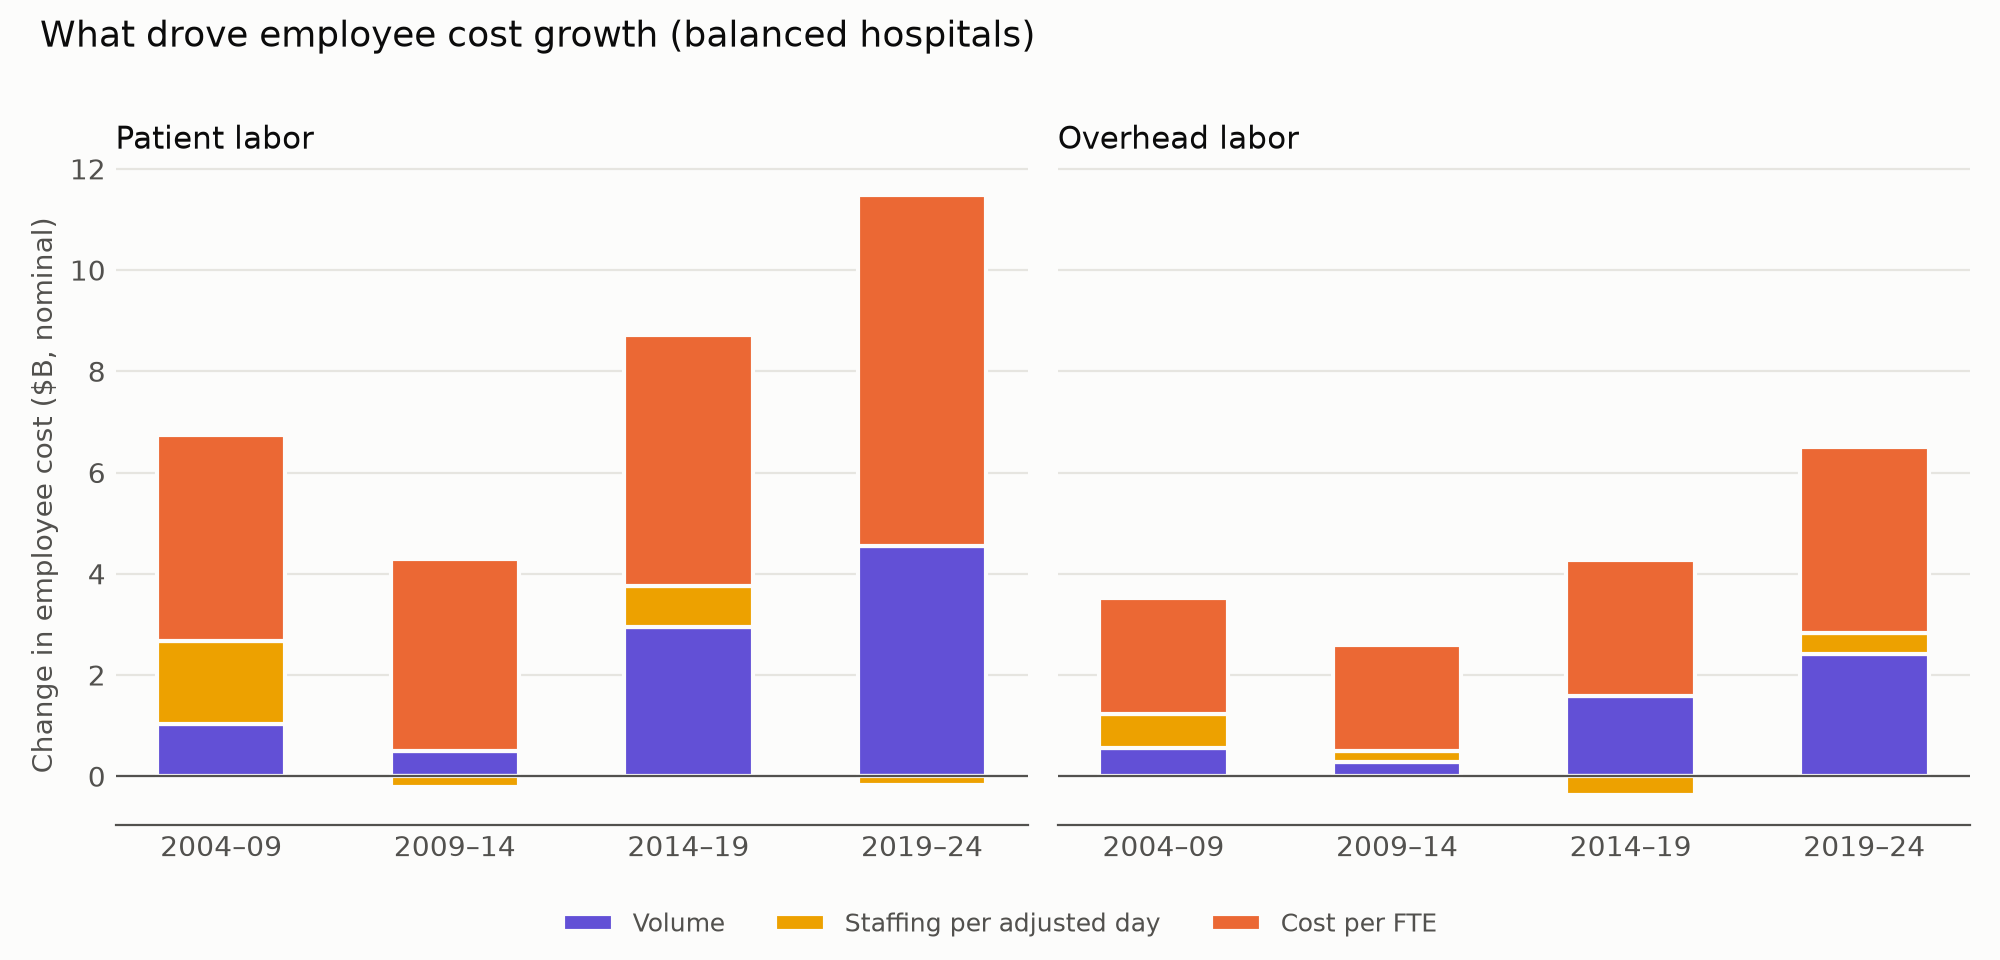

In [16]:
plots.plot_decomposition(effects, scratch / "decomposition.png", "balanced")
display(Image(filename=str(scratch / "decomposition.png"), width=760))

**How to read this:** cost per FTE is about two-thirds of employee-cost growth. Volume is about a quarter, and staffing per unit of work is under a tenth.

**Limit of the patient and overhead split:** salary is divided by hour share, so both groups end up with nearly the same cost per FTE. The split shows where the hours went. It can't show whether overhead staff got bigger raises.

In [17]:
pooled = pd.DataFrame({
    "patient": data.groupby("YEAR")["LABOR_PATIENT"].sum() / data.groupby("YEAR")["FTE_PATIENT"].sum(),
    "overhead": data.groupby("YEAR")["LABOR_OVERHEAD"].sum() / data.groupby("YEAR")["FTE_OVERHEAD"].sum(),
})
pooled.round(0)

,patient,overhead
YEAR,,
2004,"70,800.00","71,244.00"
2009,"89,773.00","91,555.00"
2014,"106,035.00","108,699.00"
2019,"125,878.00","129,336.00"
2024,"150,425.00","154,544.00"


## 6. Look beyond labor

The decomposition explains employee cost, but employee cost is less than half of the dollar growth.

In [18]:
first, last = summary.loc[2004], summary.loc[2024]
print(f"Total expense grew  ${(last['total_exp'] - first['total_exp']) / 1e9:,.1f}B")
print(f"Employee cost grew  ${(last['labor'] - first['labor']) / 1e9:,.1f}B")
print(f"Employee share of growth: {(last['labor'] - first['labor']) / (last['total_exp'] - first['total_exp']):.1%}")
(analysis.expense_mix(data) * 100).round(1)

Total expense grew  $101.9B
Employee cost grew  $47.4B
Employee share of growth: 46.5%


,EXP_SAL,EXP_BEN,EXP_PHYS,EXP_OTHPRO,EXP_SUPP,EXP_PURCH,EXP_DEPRE,EXP_LEASES,EXP_INSUR,EXP_INTRST,EXP_OTH
YEAR,,,,,,,,,,,
2004,36.60,15.40,2.80,4.40,16.20,12.30,4.20,1.30,1.20,1.40,4.10
2009,38.10,15.40,3.40,3.20,15.70,12.90,4.10,1.50,0.80,1.30,3.60
2014,35.30,15.40,4.00,2.90,14.30,14.30,4.50,1.30,0.60,1.40,5.80
2019,33.90,15.30,4.60,3.00,14.70,14.20,4.40,1.20,0.50,1.10,7.20
2024,34.00,14.10,4.90,3.20,15.70,14.30,3.50,1.00,0.50,1.10,7.70


### Overhead

Overhead follows the old notebook definition, which has six cost centers. Administrative costs grew fastest.

The sharp rise after 2009 may partly reflect California's Hospital Quality Assurance Fee, which would be a provider tax and not administrative growth. **This hasn't been verified.**

In [19]:
overhead = data.groupby("YEAR")[config.OVERHEAD_EXP_COLS].sum() / 1e9
overhead.loc["2024 as multiple of 2004"] = overhead.loc[2024] / overhead.loc[2004]
overhead.round(2)

,EXP_RES,EXP_ED,EXP_GEN,EXP_FISC,EXP_ADM,EXP_UNASSG
YEAR,,,,,,
2004,0.21,0.57,5.86,1.66,5.22,2.22
2009,0.34,0.82,8.70,2.13,7.67,2.87
2014,0.42,1.01,11.56,2.59,12.27,3.81
2019,0.55,1.24,14.95,3.40,17.83,4.78
2024,0.59,1.78,20.26,4.04,24.53,6.46
2024 as multiple of 2004,2.83,3.10,3.46,2.43,4.70,2.91


### How well does employee cost predict total expense?

For these hospitals the R² is high, but be careful with it. It's high partly because big hospitals spend more on everything. Comparing growth rates gives a much weaker link, so this number doesn't show that labor is what drives costs up.

In [20]:
analysis.variance_explained(data).round(3).to_frame()

,r2
2004,0.98
2009,0.98
2014,0.98
2019,0.97
2024,0.97
pooled,0.97


In [21]:
growth_rates = data.sort_values(["FAC_NO", "YEAR"]).copy()
for col in ["LABOR", "TOT_OP_EXP"]:
    growth_rates[f"{col}_growth"] = growth_rates.groupby("FAC_NO")[col].pct_change()
pair = growth_rates[["LABOR_growth", "TOT_OP_EXP_growth"]].replace([np.inf, -np.inf], np.nan).dropna()
print(f"R² on 5-year growth rates: {pair.corr().iloc[0, 1] ** 2:.3f}")

R² on 5-year growth rates: 0.608


## 7. Why the old notebooks gave different numbers

All three notebooks start from the same source data. `Hospital_Data.ipynb` also read repeated rows, which multiplied totals by 4. PT1 and PT2 fixed that.

The remaining gap comes from hospital choice. The notebooks keep all 357 hospitals found in every file, and that includes Kaiser. Kaiser reports no employee cost until 2024, while its FTEs are counted every year.

In [22]:
everyone = features.add_features(joined)
kaiser = everyone[everyone["TYPE_HOSP"] == "KAISER"].groupby("YEAR").agg(
    reports=("FAC_NO", "size"), employee_cost=("LABOR", "sum"), paid_fte=("FTE", "sum"), total_expense=("TOT_OP_EXP", "sum"))
kaiser[["employee_cost", "total_expense"]] /= 1e9
kaiser.round(1)

,reports,employee_cost,paid_fte,total_expense
YEAR,,,,
2004,28,0.00,"27,552.60",6.90
2009,32,0.00,"63,577.70",10.70
2014,34,0.00,"36,364.70",13.50
2019,33,0.00,"39,864.10",19.50
2024,34,9.20,"44,201.20",52.70


This cell reruns PT1's logic on the local CSVs: all 357 hospitals, with total expense taken from the department lines. It shows how the 92% and the 2.29x come from Kaiser and similar reporters.

In [23]:
files = [pd.read_csv(config.ROOT / f"Data/data_files_csv/Expenses_{year}.csv", low_memory=False) for year in YEARS]
common = set.intersection(*[set(frame["FAC_NO"]) for frame in files])
old = pd.concat([frame[frame["FAC_NO"].isin(common)] for frame in files], ignore_index=True).copy()
old["YEAR"] = pd.to_datetime(old["END_DATE"], format="mixed").dt.year
departments = ["EXP_DLY", "EXP_AMB", "EXP_ANC", "EXP_PIP", "EXP_POP", "EXP_RES", "EXP_ED", "EXP_GEN", "EXP_FISC", "EXP_ADM", "EXP_UNASSG"]
old["TOTAL"] = old[departments].sum(axis=1)
old["EMPLOYEE"] = old["EXP_SAL"] + old["EXP_BEN"]
old["COMPARABLE"] = old["TYPE_HOSP"].str.upper().eq("COMPARABLE")

r2 = lambda frame: frame["EMPLOYEE"].corr(frame["TOTAL"]) ** 2
rate_growth = lambda frame: (lambda s: (s[2024] / s[2004]))(frame.groupby("YEAR")["EMPLOYEE"].sum() / frame.groupby("YEAR")["HOSP_FTE"].sum())

pd.DataFrame({
    "rows": [len(old), (old["EMPLOYEE"] > 0).sum(), old["COMPARABLE"].sum()],
    "R²": [r2(old), r2(old[old["EMPLOYEE"] > 0]), r2(old[old["COMPARABLE"]])],
    "cost per FTE growth": [rate_growth(old), rate_growth(old[old["EMPLOYEE"] > 0]), rate_growth(old[old["COMPARABLE"]])],
}, index=["PT1: all 357 hospitals", "Without zero-pay rows", "Comparable rows only"]).round(3)

,rows,R²,cost per FTE growth
PT1: all 357 hospitals,1805,0.92,2.29
Without zero-pay rows,1641,0.97,2.16
Comparable rows only,1577,0.97,2.12


The first row matches PT1's saved results. Removing the rows with no reported pay lifts R² straight away. Using comparable hospitals only brings cost per FTE growth close to the pipeline's 2.14x.

The FTEs +20% in the old project notes doesn't match any 2004 to 2024 figure. The next cell shows it's close to growth measured from 2009.

In [24]:
fte = old.groupby("YEAR")["HOSP_FTE"].sum()
print(f"FTE growth 2004 to 2024: {fte[2024] / fte[2004] - 1:+.0%}")
print(f"FTE growth 2009 to 2024: {fte[2024] / fte[2009] - 1:+.0%}")

FTE growth 2004 to 2024: +51%
FTE growth 2009 to 2024: +21%


## 8. Test how much the choices matter

A result you can trust shouldn't flip when a reasonable choice changes.

In [25]:
variants = {
    "All 5 years (headline)": features.add_features(hospitals["balanced"]),
    "All comparable": features.add_features(hospitals["comparable"]),
    "All 5 years, rescaled to 365 days": features.add_features(clean.select_cohort(clean.annualize(joined), "balanced")),
}
rows = {}
for name, frame in variants.items():
    s = analysis.yearly_summary(frame)
    e = decompose.decompose(frame, 2004, 2024)
    by_factor = e.groupby("factor")["share_of_change"].sum()
    rows[name] = {
        "expense x": s["total_exp"][2024] / s["total_exp"][2004],
        "cost per FTE x": s["cost_per_fte"][2024] / s["cost_per_fte"][2004],
        "wage share %": by_factor["wage"] * 100,
        "volume share %": by_factor["volume"] * 100,
        "staffing share %": by_factor["staffing"] * 100,
    }
pd.DataFrame(rows).T.round(2)

,expense x,cost per FTE x,wage share %,volume share %,staffing share %
All 5 years (headline),3.46,2.14,65.39,25.88,8.73
All comparable,3.26,2.12,68.52,21.10,10.38
"All 5 years, rescaled to 365 days",3.47,2.14,65.28,26.05,8.67


The main story holds in all three. Cost per FTE stays the largest driver.

### Audit status

Most 2024 reports are still In Process, so 2024 figures may change. Audited and in-process hospitals may also differ in other ways, so this gap isn't purely an audit effect.

In [26]:
display(summary[["hospitals", "in_process"]])
latest = data[data["YEAR"] == 2024].groupby("DATA_IND")[["LABOR", "FTE"]].sum()
latest["cost_per_fte"] = latest["LABOR"] / latest["FTE"]
latest.round(0)

,hospitals,in_process
YEAR,,
2004,310,0
2009,310,55
2014,310,0
2019,310,0
2024,310,240


,LABOR,FTE,cost_per_fte
DATA_IND,,,
AUDITED,15239772225,"107,169.00","142,203.00"
IN PROCESS,53661868741,"346,616.00","154,816.00"


## 9. From results to the dashboard

The dashboard doesn't recalculate anything. The steps are:

1. `python -m src.pipeline --cohort <name>` writes results to `outputs/<name>/`.
2. `python -m src.dashboard_data` turns them into four JSON files in `outputs/dashboard/`.
3. Those files are uploaded to the dashboard.
4. The page filters them and draws the charts in your browser.

| File | Feeds |
|---|---|
| `metrics.json` | Summary figures, growth chart, overhead chart, coverage table |
| `decomposition.json` | Employee-cost chart and driver table |
| `expenses.json` | Where the dollars grew |
| `hospitals.json` | Hospital search table |

The dashboard's hospital group buttons switch between the three versions in Part 8.

[Open the dashboard](https://claude.ai/artifact/YFxmn1N2T3DZzDKaDVEW48)

**To refresh it after a change,** run the commands below from the project folder, then replace the files in the dashboard's Sources panel.

```
.venv/bin/python -m src.pipeline --cohort comparable
.venv/bin/python -m src.pipeline --cohort balanced
.venv/bin/python -m src.pipeline --cohort balanced --annualize
.venv/bin/python -m src.dashboard_data
```

In [27]:
import json

for name in ["metrics", "decomposition", "expenses", "hospitals"]:
    rows = json.loads((config.OUTPUT_DIR / "dashboard" / f"{name}.json").read_text())
    print(f"{name + '.json':20s} {len(rows):4d} rows   columns: {', '.join(list(rows[0])[:6])} ...")

metrics.json           15 rows   columns: year, hospitals, in_process, multi_report, total_exp, labor ...
decomposition.json     90 rows   columns: cohort, period, start, end, group, factor ...
expenses.json         105 rows   columns: year, dollars, cohort, category ...
hospitals.json        310 rows   columns: fac_no, hospital, day_start, day_end, fte_start, fte_end ...


This final check confirms the notebook matches the saved pipeline results.

In [28]:
saved = pd.read_csv(config.OUTPUT_DIR / "balanced" / "summary.csv", index_col="YEAR")
for col in ["total_exp", "labor", "fte", "overhead_exp_per_fte"]:
    assert np.allclose(saved[col], summary[col]), col
print("Notebook matches outputs/balanced/summary.csv")

Notebook matches outputs/balanced/summary.csv


## Summary

- Expense grew about 3.5x for the 310 hospitals reporting in all 5 years.
- Inpatient discharges were flat, but adjusted patient days rose about 35% and FTEs about 50%.
- Cost per FTE about doubled and is about two-thirds of employee-cost growth.
- Employee cost is under half of total expense growth, so most of the increase sits outside this decomposition.
- Administrative costs grew fastest, and the possible provider-fee link still needs checking.

**Still to do:** add medical CPI so results can be shown in real dollars. Until then, part of the cost per FTE driver is general price and wage inflation.